[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eliem08/ai-agents-healthcare-labs/blob/main/notebooks/Lab00_Setup_Check.ipynb)

# Lab 0 — Get ready
**AI Agents for Healthcare and Diagnostics** · about 20–25 minutes · complete it **before Day 1**

All labs of this course take place in the **Northbridge Clinical & Research Laboratory**, a *fictional*
laboratory. Every dataset is synthetic or public — no real patient data is ever used.

**At the end of this lab you will have:**
- your own Gemini API key, stored safely in Colab;
- built your first AI agent, seen it look up laboratory data with a tool, and verified its answer;
- checked which Gemini tools your account can use;
- a status card to send to the trainer.

**Before you start**
- A Google account (your work account if your organisation allows it) and Chrome or Edge.
- About 20–25 minutes. Nothing to install — everything runs in the browser.
- You can stop and come back. Colab may restart in the meantime; if a later cell then says
  `NameError: ... is not defined`, click that cell and use the menu **Runtime → Run before**.

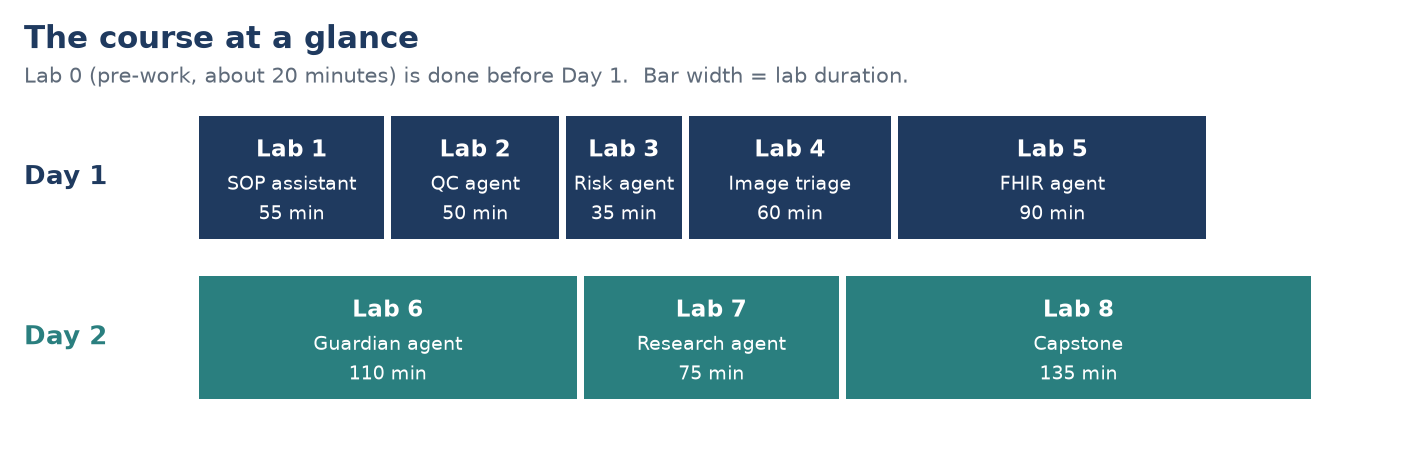

*The course at a glance. This lab (Lab 0) prepares everything you need for Day 1.*

### How every lab works
Each lab is a series of numbered **tasks**. Every task has the same parts:

| Part | What it is |
|---|---|
| **Your task** | what to do and why, in one sentence |
| **Steps** | the steps, in plain words |
| **YOUR CELL** | a cell to complete: replace every `___` (in a form, type into the box) |
| **CHECK** | a folded cell that tells you what is right and exactly what to fix |
| **Hint / Solution** | folded; open only if you are stuck |

Each task says where it happens: **in the notebook**, **in the Gemini app** (no code), or **optional challenge**.

**To run a cell:** click the round run button on its left, or press **Shift + Enter**. Run cells from top to
bottom. Cells whose code is folded show only a title: just run them.

| Term | Meaning in this course |
|---|---|
| **Model** | Gemini, the AI that reads and writes text |
| **Agent** | a model + your **instruction** (the rules) + the **tools** it may use |
| **Tool** | an ordinary Python function the agent can call: it computes, the model decides |
| **API key** | your personal password that lets this notebook talk to Gemini |
| **Colab Secrets** | the panel (key icon, left sidebar) where Colab keeps your key hidden |
| **Trace** | the record of every step the agent took: which tool, which data, which conclusion |

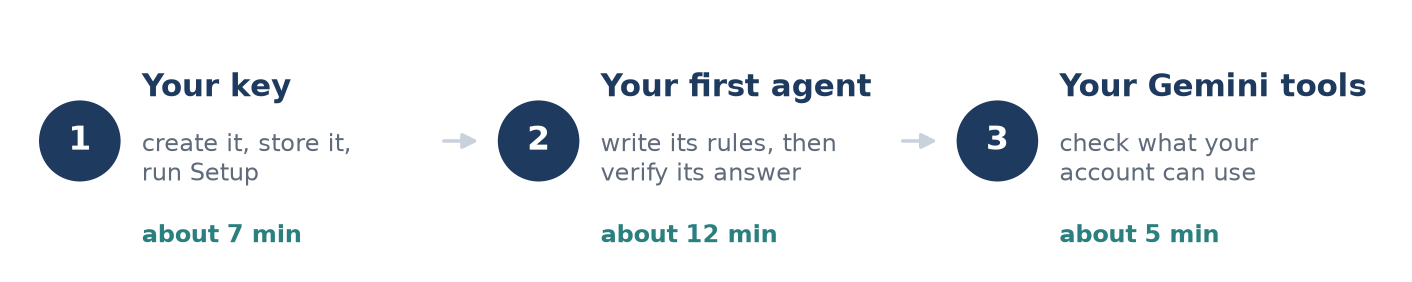

*Lab 0 in three parts.*

## Part 1 — Your key

### Task 1 — Save your own copy
<sub>IN THE NOTEBOOK · ABOUT 1 MIN</sub>

**Your task.** Make a personal copy of this notebook, so that your work is kept.

**Steps**

1. In the menu, click **File → Save a copy in Drive**.
2. A new tab opens with *Copy of Lab00…* — **work in that tab** from now on.
3. You can close the original tab.

**CHECK** — the title at the top-left of the page now starts with **Copy of**.

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Don't see *Save a copy in Drive*? Check that you are signed in to Google (top-right corner). If your organisation blocks Drive, you can still work in this tab — just don't close it.

</details>

### Task 2 — Create your Gemini API key and store it in Colab Secrets
<sub>IN THE NOTEBOOK · ABOUT 5 MIN</sub>

**Your task.** Give this notebook a safe way to talk to Gemini.

**Steps**

1. Open **[aistudio.google.com/apikey](https://aistudio.google.com/apikey)** in a new tab and sign in.
2. Click **Create API key**, then copy the key — a long code that starts with `AQ.` or `AIza`. Never paste it into a cell, a chat or an email.
3. Back here, click the **key icon** in the left sidebar (Secrets), then **Add new secret**.
4. Name: `GOOGLE_API_KEY` (exactly). Value: paste your key.
5. Switch **Notebook access** on. The Setup cell below will test the key.

**CHECK** — the Setup cell below shows **OK** for *API key found* and *API key works*.

<details><summary><b>Hint</b> — open only if you are stuck</summary>

- **Your work account cannot create a key?** Your organisation may restrict AI Studio. Ask the trainer whether
  a personal Google account is allowed for this course (it only uses synthetic data).
- **The name must be exactly** `GOOGLE_API_KEY` (capitals and underscores).
- **Forgot the toggle?** Open Secrets again and switch *Notebook access* on for this notebook.
- **About the free tier:** Google may use what you send through a free key to improve its products. That is
  why this course uses synthetic data only — **never paste real patient or company data** into a notebook
  or a prompt. You can delete the key in AI Studio after the course.

</details>

### Setup — run this cell (about 1 minute)
It installs the course tools, downloads the course files and checks everything.
The code is folded on purpose: you don't need to read it.

**The first time, Colab may show two pop-ups:**
*"Warning: This notebook was not authored by Google"* → click **Run anyway** (it comes from the course).
*"Allow access to secret GOOGLE_API_KEY?"* → click **Grant access**.

In [ ]:
# @title Setup — click run and wait about 1 minute
import os, subprocess, sys
REPO = "https://github.com/eliem08/ai-agents-healthcare-labs"
MODEL = "gemini-3.5-flash-lite"  # @param {type:"string"}
___ = "___"  # the blank you will replace in YOUR CELL

def _step(what, cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(f"FAILED: {what}. Run this cell again; if it fails twice, send the text below to the trainer:")
        print((r.stderr or r.stdout)[-800:])
        return False
    print(f"done: {what}")
    return True

try:
    import google.colab  # noqa: F401  — present only inside Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

_ready = True
if IN_COLAB:                                            # in Colab: download course + install tools
    if not os.path.exists("/content/course"):
        _ready = _step("download course files", ["git", "clone", "-q", "--depth", "1", REPO, "/content/course"])
    if _ready:
        _ready = _step("install Google ADK", [sys.executable, "-m", "pip", "install", "-q", "google-adk==2.15.0"])
    sys.path.insert(0, "/content/course")

SETUP_OK, SETUP_RESULTS = False, []
if _ready:
    from google.adk.agents import Agent
    from labkit.setup import check_environment, show_checks
    from labkit.agents import make_model, run, DETERMINISTIC
    from labkit.ui import check, has_blank, ready, copy_box, done_card
    SETUP_RESULTS = check_environment(MODEL)
    SETUP_OK = show_checks(SETUP_RESULTS)

**What you should see:** every line marked **OK**, then *"Everything is ready"*.

**If it does not work**

| You see | Do this |
|---|---|
| FIX — API key found | Redo Task 2: name `GOOGLE_API_KEY`, *Notebook access* on, run Setup again |
| FIX — API key works, "rejected" | Create a new key in AI Studio and replace it in Secrets |
| FIX — API key works, "busy" or "quota" | Wait 30–60 seconds, run Setup again |
| FIX — PubMed reachable | Not blocking today — but tell the trainer (Lab 7 needs it) |
| FAILED: download / install | Run Setup again; if it fails twice, send the text to the trainer |
| `NameError: ... is not defined` in later cells | Session restarted: click the cell, then **Runtime → Run before** |

## Part 2 — Your first agent

An **agent** is a model that can **decide to use tools**. You write its **instruction** (the rules),
you give it **tools** (Python functions), and it decides when to call them. Every step is recorded in a
**trace**, so you — the human — can check what it did.

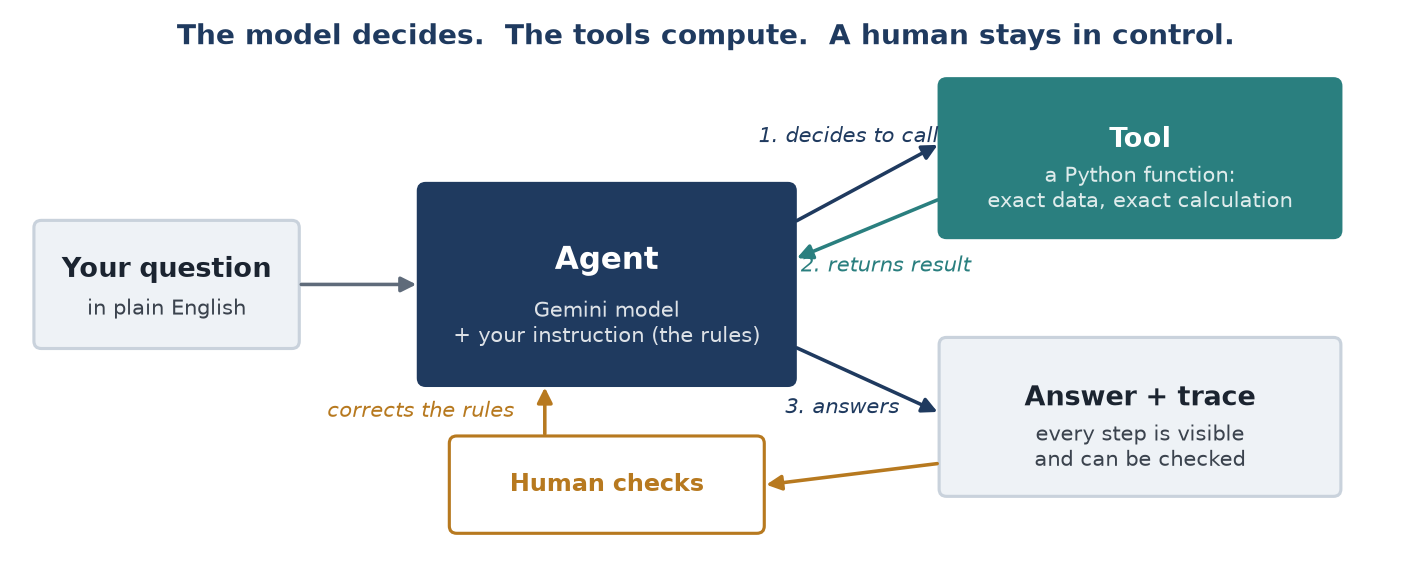

*The key idea of the whole course: the model decides, the tools compute, a human stays in control.*

### The tool: the Northbridge test catalogue
Your agent will answer colleagues' questions about laboratory tests. It gets one tool: a lookup in the
Northbridge **test catalogue** (container, minimum sample volume, sample stability, turnaround time).
The catalogue is folded in the next cell — run it.

In [ ]:
# @title Northbridge test catalogue (fictional values, for training only) — run this cell
CATALOGUE_NOTE = ("Fictional Northbridge catalogue for training. Tube cap colours follow the BD convention; other "
                  "manufacturers differ — always go by the additive. Room temperature = 15–25 °C.")
CATALOGUE = {
    "25-hydroxyvitamin D (D2 + D3)": {
        "aliases": ["25-OH vitamin D", "25-OH D", "25(OH)D", "vitamin D", "25-hydroxyvitamin D"],
        "method": "LC-MS/MS", "specimen": "serum",
        "container": "serum tube with clot activator and gel (SST; gold top, BD convention)",
        "minimum_sample_volume_mL": 0.5, "turnaround": "2 working days",
        "stability": {"room temperature": "7 days", "2–8 °C": "14 days", "−20 °C": "3 months"}},
    "Testosterone (total)": {
        "aliases": ["testosterone", "total testosterone"],
        "method": "LC-MS/MS", "specimen": "serum",
        "container": "plain serum tube without gel (red top, BD convention) — gel tubes not accepted",
        "collection": "before 10:00", "minimum_sample_volume_mL": 0.5, "turnaround": "3 working days",
        "stability": {"room temperature": "24 hours", "2–8 °C": "7 days", "−20 °C": "3 months"}},
    "Potassium": {
        "aliases": ["potassium", "plasma potassium", "K+"],
        "method": "indirect ion-selective electrode (ISE)", "specimen": "lithium-heparin plasma",
        "container": "lithium-heparin tube (green top, BD convention)",
        "minimum_sample_volume_mL": 0.5, "turnaround": "1 hour",
        "stability": {"unseparated, room temperature": "4 hours — do not refrigerate unseparated blood",
                      "separated plasma, 2–8 °C": "7 days"}},
    "Glucose": {
        "aliases": ["glucose", "plasma glucose"],
        "method": "hexokinase", "specimen": "fluoride-oxalate plasma",
        "container": "sodium fluoride / potassium oxalate tube (grey top, BD convention)",
        "minimum_sample_volume_mL": 0.5, "turnaround": "1 hour",
        "stability": {"room temperature": "24 hours", "2–8 °C": "3 days"}},
    "HbA1c": {
        "aliases": ["HbA1c", "A1c", "glycated haemoglobin", "glycated hemoglobin"],
        "method": "HPLC", "specimen": "EDTA whole blood",
        "container": "K2-EDTA tube (lavender top, BD convention)",
        "minimum_sample_volume_mL": 1.0, "turnaround": "1 working day",
        "stability": {"room temperature": "3 days", "2–8 °C": "7 days"}},
    "TSH": {
        "aliases": ["TSH", "thyroid-stimulating hormone", "thyrotropin"],
        "method": "electrochemiluminescence immunoassay (ECLIA)", "specimen": "serum",
        "container": "serum tube with clot activator and gel (SST; gold top, BD convention)",
        "minimum_sample_volume_mL": 0.5, "turnaround": "1 working day",
        "stability": {"room temperature": "24 hours", "2–8 °C": "7 days"}},
}
print(f"Catalogue loaded: {len(CATALOGUE)} tests —", "; ".join(CATALOGUE))

And here is the tool itself. It is an ordinary Python function. Its **description** (the text in triple quotes)
is what the model reads to decide when to use it — so it matters as much as the code. Notice that it only
accepts an **exact** test name or a known alias: a "close enough" match could silently return the wrong test.
Try it by hand.

In [ ]:
def get_test_info(test_name: str) -> dict:
    """Look up a laboratory test in the Northbridge test catalogue.

    Returns the method, specimen, container, minimum sample volume (mL), sample stability and turnaround time.
    Use the test name, for example '25-OH vitamin D', 'potassium' or 'HbA1c'.
    """
    def norm(s):
        return "".join(ch for ch in s.lower() if ch.isalnum())
    for name, info in CATALOGUE.items():
        if norm(test_name) in {norm(name), *(norm(a) for a in info["aliases"])}:
            entry = {k: v for k, v in info.items() if k != "aliases"}
            return {"found": True, "test": name, **entry, "note": CATALOGUE_NOTE}
    return {"found": False,
            "message": f"No exact match for '{test_name}' in the Northbridge catalogue. Do not substitute another test.",
            "tests_in_catalogue": list(CATALOGUE)}

get_test_info("vitamin D")   # exactly what the agent will receive when it calls the tool

### Task 3 — Write your agent's rules
<sub>IN THE NOTEBOOK · ABOUT 4 MIN</sub>

**Your task.** Write the rules of a *test catalogue assistant* and choose its tool.

**Steps**

1. **Name:** a short name with letters and `_` only, for example `catalogue_assistant`.
2. **Instruction, rule 1:** tell it to *always use `get_test_info`* for any question about a laboratory test.
3. **Instruction, rule 2:** tell it what to do when the catalogue does not contain the answer — *say that it does not know*, and never invent or estimate a number.
4. **Tools:** put `get_test_info` in the list — no quotation marks, no `()`.
5. Run your cell, then run the CHECK cell.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
AGENT_NAME = "___"
INSTRUCTION = """___"""
TOOLS = [___]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_instr = INSTRUCTION.lower()
_ok = check([
    (has_blank(AGENT_NAME) is None and AGENT_NAME.isidentifier(), "Name filled (letters and _ only)",
     'Write a name like "catalogue_assistant" — no spaces.'),
    (has_blank(INSTRUCTION) is None and "get_test_info" in INSTRUCTION, "Rule 1: the instruction names the tool",
     "Write in the instruction that it must use get_test_info for questions about a test."),
    (any(p in _instr for p in ("don't know", "do not know", "not know", "say you don", "say that you don"))
     and any(p in _instr for p in ("invent", "estimate", "guess", "make up")),
     "Rule 2: say 'I don't know' and never invent",
     "Write both parts: say you don't know when the catalogue lacks the answer, and never invent/estimate."),
    (TOOLS == [get_test_info], "Tool chosen: get_test_info", "Write TOOLS = [get_test_info] (no quotes, no ())."),
])

<details><summary><b>Hint</b> — open only if you are stuck</summary>

The instruction is plain English inside the triple quotes. You could start like this:
`"""You answer questions about laboratory tests. Always use get_test_info ... If ..., say you don't know. Never invent ..."""`

</details>

<details><summary><b>Solution</b> — open only after trying</summary>

```python
AGENT_NAME = "catalogue_assistant"
INSTRUCTION = """You answer colleagues' questions about laboratory tests at Northbridge.
Rule 1: for any question about a test (container, volume, stability, turnaround), ALWAYS call get_test_info first.
Rule 2: if the catalogue does not contain the answer, say clearly that you don't know. Never invent or estimate a number."""
TOOLS = [get_test_info]
```

</details>

### Build the agent
This is how an agent is created with Google's **Agent Development Kit (ADK)**: a name, a model, your
instruction, your tools. `DETERMINISTIC` sets the temperature to 0, so the same question gives the same answer —
a course rule for reproducibility. Run it (and run it again whenever you change your rules).

In [ ]:
if ready(AGENT_NAME, INSTRUCTION, TOOLS):        # stops here with a clear message if a ___ is left
    my_agent = Agent(
        name=AGENT_NAME,
        model=make_model(MODEL),
        instruction=INSTRUCTION,
        tools=TOOLS,
        generate_content_config=DETERMINISTIC,
    )
    print(f"Agent '{my_agent.name}' built with tool(s): {[t.__name__ for t in TOOLS]}")
else:
    my_agent = None

### Ask your agent — question 1
A clinician requests 25-OH vitamin D. Read the **trace** under the cell:
*TOOL CALL* (the agent decides to look up the test), *TOOL RESULT* (the exact catalogue entry),
*ANSWER* (what the agent concluded). Each question starts a fresh conversation: the agent does not remember
previous questions.

In [ ]:
result1 = run(my_agent, "A clinician requests 25-OH vitamin D. Which container do we need, what minimum sample "
                        "volume, and how long is the sample stable at room temperature?")

In [ ]:
# @title CHECK — did your agent use the catalogue and answer correctly?
if not result1.message:
    _t = result1.text.lower()
    _ok = check([
        ("get_test_info" in result1.tool_calls, "Your agent looked up the test with its tool",
         "Make rule 1 stronger (ALWAYS call get_test_info), run your rules cell and the build cell again."),
        (any(w in _t for w in ("sst", "gel", "gold")) and "0.5" in _t and "7 day" in _t,
         "Its answer matches the catalogue (SST, 0.5 mL, 7 days at room temperature)",
         "Compare the ANSWER with the TOOL RESULT above. Ask again, or strengthen rule 1."),
    ])

### Task 4 — Verify the answer against the source
<sub>IN THE NOTEBOOK · ABOUT 3 MIN</sub>

**Your task.** Do what a careful scientist does with any AI answer: check it against the source data in the trace.

**Steps**

1. Look at the **TOOL RESULT** of question 1 above (not at the ANSWER).
2. Read the **room-temperature stability** and the **minimum sample volume** in it.
3. Type them into the two boxes of the form below, exactly as you read them, then run the cell.
4. Then run the CHECK: it compares what *you* read with the catalogue.

In [ ]:
# @title Type what the TOOL RESULT says, then run this cell
# YOUR CELL — tick the boxes in the form, then run this cell
rt_stability = "___"  # @param {type:"string"}
minimum_volume_mL = "___"  # @param {type:"string"}

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_vd = CATALOGUE["25-hydroxyvitamin D (D2 + D3)"]
_norm = lambda s: "".join(ch for ch in str(s).lower() if ch.isalnum() or ch == ".")
VERIFIED = (_norm(rt_stability) == _norm(_vd["stability"]["room temperature"])
            and _norm(minimum_volume_mL).rstrip("ml") in {_norm(_vd["minimum_sample_volume_mL"]), "0.50"})
_ok = check([
    (_norm(rt_stability) == _norm(_vd["stability"]["room temperature"]), "Room-temperature stability read correctly",
     "Look again at the TOOL RESULT, line 'stability', entry 'room temperature'."),
    (_norm(minimum_volume_mL).rstrip("ml") in {_norm(_vd["minimum_sample_volume_mL"]), "0.50"},
     "Minimum sample volume read correctly", "Look again at the TOOL RESULT, line 'minimum_sample_volume_mL'."),
])

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Scroll up to question 1. In the green-bordered **TOOL RESULT** card, find the lines `stability` and `minimum_sample_volume_mL`. Type the values only, e.g. `7 days` and `0.5`.

</details>

### Question 2 — what the catalogue does *not* say
The catalogue gives vitamin D stability at room temperature, 2–8 °C and −20 °C. It says **nothing about −80 °C**.
A general AI model "knows" that frozen samples usually last longer, and is tempted to extrapolate. In a
laboratory, an extrapolated stability claim is an unvalidated claim. Does your rule 2 hold?

In [ ]:
result2 = run(my_agent, "Can a 25-OH vitamin D sample be stored at −80 °C for one year?")

In [ ]:
# @title CHECK — did your agent refuse to extrapolate?
if not result2.message:
    _t = result2.text.lower()
    _admits = any(p in _t for p in ("not specified", "not listed", "not include", "does not", "doesn't", "no information",
                                   "not in the catalogue", "not contain", "only", "don't know", "do not know",
                                   "cannot confirm", "can't confirm", "not available"))
    _claims_yes = _t.strip().startswith("yes")
    _ok = check([
        (_admits and not _claims_yes, "It said the catalogue does not cover −80 °C (no extrapolation)",
         "Your agent extrapolated a stability claim. Make rule 2 stricter (only state what the catalogue says), "
         "rebuild the agent, ask again."),
    ])

> **Why this matters.** An extrapolated or invented value can look perfectly plausible — and be wrong for your
> method, your population and your validation. In **Lab 1** you will meet an assistant with *no* tool and *no*
> rule 2, and count how often it invents numbers about laboratory procedures.

### Task 5 — Try to make your agent slip
<sub>OPTIONAL CHALLENGE · ABOUT 3 MIN</sub>

**Your task.** Probe your agent with tricky questions, and verify every claim against the trace.

**Steps**

1. Write a tricky question in the box — see the hint for ideas.
2. Run the cell and read the trace.
3. Verify: is **every number and every claim** in the ANSWER supported by the TOOL RESULT?

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
MY_QUESTION = "___"
my_result = run(my_agent, MY_QUESTION) if has_blank(MY_QUESTION) is None else print(has_blank(MY_QUESTION))

**CHECK** — you checked every claim of the ANSWER against the TOOL RESULT. This habit — *verify against the source* — is the core skill of the whole course.

<details><summary><b>Hint</b> — open only if you are stuck</summary>

- *"What is the adult reference range for ferritin?"* — ferritin is not in the catalogue.
- *"Do you measure free testosterone?"* — only **total** testosterone is listed.
- *"Can I send vitamin D in a lavender-top tube?"* — "not listed" is not the same as "not acceptable":
  does the agent say so honestly?

</details>

## Part 3 — Your Gemini tools

### Task 6 — Check your Gemini tools
<sub>IN THE GEMINI APP · ABOUT 5 MIN</sub>

**Your task.** Find out which Gemini tools your work account can use — several labs use them.

**Steps**

1. Open **[gemini.google.com](https://gemini.google.com)** with your **work** account.
2. **Skills** — look for *Skills* in the menu. If you only see *Gems*, tick Skills too: Gems are being replaced by Skills and work the same way for this course.
3. **Gemini Notebook** (formerly NotebookLM) — open [notebooklm.google.com](https://notebooklm.google.com) or find *Notebooks* in Gemini.
4. **Canvas, Deep Research, image generation** — in the Gemini chat, open the **tools menu** next to the message box and see which are listed. Try one: ask *"Create a one-page checklist for specimen labelling"* with **Canvas**.
5. In the form below, tick each tool you found, then run the cell.

In [ ]:
# @title Tick the tools you found, then run this cell
# YOUR CELL — tick the boxes in the form, then run this cell
gemini_app = False  # @param {type:"boolean"}
skills_or_gems = False  # @param {type:"boolean"}
gemini_notebook = False  # @param {type:"boolean"}
canvas = False  # @param {type:"boolean"}
deep_research = False  # @param {type:"boolean"}
image_generation = False  # @param {type:"boolean"}

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
TOOLS_FOUND = {"Gemini app": gemini_app, "Skills (or Gems)": skills_or_gems, "Gemini Notebook": gemini_notebook,
               "Canvas": canvas, "Deep Research": deep_research, "Image generation": image_generation}
_ok = check([(v, k, "Not found? Tell the trainer before Day 1.") for k, v in TOOLS_FOUND.items()],
            optional=True)

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Menus change often. If you can't find a tool within two minutes, leave its box unticked and move on —
the trainer will check access with your organisation. Every lab has a path that works without it.

</details>

## What you learned
1. **An agent = a model + your instruction + tools.** The facts come from the tool, not from the model's memory.
2. **The trace lets a human verify every step** — which tool was called, what data came back, what was concluded.
   You did it yourself in Task 4.
3. **One clear rule changes behaviour:** "if the source doesn't say it, say you don't know" stops the agent from
   inventing or extrapolating. Lab 1 measures how much this matters.

## Finish — your status card
Type your name in the box, run the cell, take a screenshot of the card and post it in the course chat.
The card tells the trainer whether everything is ready for Day 1.

In [ ]:
# @title Status card — type your name, run, then screenshot the card
participant_name = ""  # @param {type:"string"}
import datetime, google.adk as _adk
_g = globals()
_lines = [f"Participant: {participant_name.strip() or 'NAME MISSING — type it in the box'}",
          f"Date: {datetime.date.today().isoformat()} · Google ADK {_adk.__version__} · model {_g.get('MODEL', '?')}"]
_lines += [f"{'OK ' if r.ok else 'FIX'} — {r.name}: {r.detail}" for r in _g.get("SETUP_RESULTS", [])]
_used = "result1" in _g and "get_test_info" in result1.tool_calls
_lines.append(f"{'OK ' if _used else 'FIX'} — First agent used its tool")
_lines.append(f"{'OK ' if _g.get('VERIFIED') else 'FIX'} — Answer verified against the source (Task 4)")
_lines.append(f"Gemini tools found: {sum(TOOLS_FOUND.values()) if 'TOOLS_FOUND' in _g else 0} of 6")
_notes = [r.note for r in (_g.get("result1"), _g.get("result2")) if r is not None and getattr(r, "note", "")]
if _notes:
    _lines.append("Note: a backup model answered at least once (Gemini was busy)")
done_card("Lab 0 — status", _lines,
          complete=bool(_g.get("SETUP_OK")) and _used and bool(_g.get("VERIFIED")) and bool(participant_name.strip()))

**Next: Lab 1 — Spot the hallucination.** You will compare a "helpful" laboratory assistant with a grounded
one, on questions about realistic laboratory SOPs, and count every invented number.

*Course material for training only. Northbridge Clinical & Research Laboratory and its catalogue are fictional.*